# Coffee Analysis

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

sentinel = -2147483648

exports = pd.read_csv("Coffee_export-1.csv", na_values=[sentinel])
imports = pd.read_csv("Coffee_import-1.csv", na_values=[sentinel])
production = pd.read_csv("Coffee_production-1.csv", na_values=[sentinel])

export_year_cols = exports.drop(columns=["Country", "Total_export"]).columns
exports[export_year_cols] = exports[export_year_cols].interpolate(method="linear", axis=1)
exports["Total_export"] = exports[export_year_cols].sum(axis=1)
exports.drop_duplicates()

import_year_cols = imports.drop(columns=["Country"]).columns
import_gap = (imports[import_year_cols].sum(axis=1) - imports["Total_import"]).abs().max()
imports.drop_duplicates()

production_year_cols = exports.drop(columns=["Country", "Total_export"]).columns
production["Coffee type"] = (
    production["Coffee type"]
    .str.strip()
    .replace({"Robusta/Arabica": "Arabica/Robusta"})
)
production.drop_duplicates()

,Country,Coffee type,1990/91,1991/92,1992/93,1993/94,1994/95,1995/96,1996/97,1997/98,...,2011/12,2012/13,2013/14,2014/15,2015/16,2016/17,2017/18,2018/19,2019/20,Total_production
0,Angola,Arabica/Robusta,3.000000e+06,4.740000e+06,4.680000e+06,1.980000e+06,4.620000e+06,3.720000e+06,4.260000e+06,3.840000e+06,...,1.740000e+06,1.980000e+06,2.100000e+06,2.340000e+06,2.460000e+06,2.700000e+06,2.100000e+06,2.520000e+06,3.120000e+06,8.208000e+07
1,Bolivia (Plurinational State of),Arabica,7.380000e+06,6.240000e+06,7.200000e+06,3.060000e+06,7.020000e+06,8.520000e+06,7.500000e+06,8.460000e+06,...,7.920000e+06,6.300000e+06,7.200000e+06,6.000000e+06,5.040000e+06,4.680000e+06,5.040000e+06,4.980000e+06,4.860000e+06,2.070000e+08
2,Brazil,Arabica/Robusta,1.637160e+09,1.637580e+09,2.076180e+09,1.690020e+09,1.691520e+09,1.083600e+09,1.751820e+09,1.568880e+09,...,2.915520e+09,3.325080e+09,3.281340e+09,3.198300e+09,3.172260e+09,3.407280e+09,3.164400e+09,3.907860e+09,3.492660e+09,7.508298e+10
3,Burundi,Arabica/Robusta,2.922000e+07,4.002000e+07,3.720000e+07,2.358000e+07,3.984000e+07,2.604000e+07,2.406000e+07,1.500000e+07,...,1.224000e+07,2.436000e+07,9.780000e+06,1.488000e+07,1.614000e+07,1.176000e+07,1.212000e+07,1.224000e+07,1.632000e+07,6.236400e+08
4,Ecuador,Arabica/Robusta,9.024000e+07,1.274400e+08,7.110000e+07,1.241400e+08,1.425600e+08,1.132800e+08,1.195800e+08,7.146000e+07,...,4.950000e+07,4.968000e+07,3.996000e+07,3.864000e+07,3.864000e+07,3.870000e+07,3.744000e+07,2.976000e+07,3.354000e+07,1.900380e+09
5,Indonesia,Arabica/Robusta,4.464600e+08,5.095800e+08,3.341400e+08,4.045800e+08,3.220800e+08,2.743800e+08,4.932600e+08,4.572600e+08,...,4.133400e+08,7.842000e+08,7.740600e+08,6.567600e+08,7.551000e+08,6.924600e+08,6.511200e+08,5.770800e+08,6.859800e+08,1.540488e+10
6,Madagascar,Robusta,5.892000e+07,5.598000e+07,6.732000e+07,2.652000e+07,3.846000e+07,4.710000e+07,5.094000e+07,3.744000e+07,...,3.510000e+07,3.000000e+07,3.504000e+07,3.006000e+07,2.484000e+07,2.718000e+07,2.424000e+07,2.274000e+07,2.298000e+07,1.045560e+09
7,Malawi,Arabica,6.300000e+06,7.440000e+06,8.220000e+06,3.720000e+06,5.040000e+06,5.460000e+06,2.940000e+06,3.660000e+06,...,1.560000e+06,1.380000e+06,1.680000e+06,1.500000e+06,1.260000e+06,1.200000e+06,8.400000e+05,7.800000e+05,9.600000e+05,8.226000e+07
8,Papua New Guinea,Arabica/Robusta,5.778000e+07,4.482000e+07,5.400000e+07,6.114000e+07,6.834000e+07,6.012000e+07,6.534000e+07,6.444000e+07,...,8.484000e+07,4.296000e+07,5.010000e+07,4.788000e+07,4.272000e+07,7.026000e+07,4.404000e+07,5.580000e+07,4.512000e+07,1.803120e+09
9,Paraguay,Arabica,7.860000e+06,4.800000e+06,3.240000e+06,4.020000e+06,1.500000e+06,1.560000e+06,1.860000e+06,2.940000e+06,...,1.200000e+06,1.200000e+06,1.200000e+06,1.200000e+06,1.200000e+06,1.200000e+06,1.200000e+06,1.200000e+06,1.200000e+06,6.222000e+07


---
## Request 1 — Largest Coffee Exporter

**Scenario:** The executive team wants to understand which countries historically
dominated the global supply chain during the early 1990s.

**Task:** Determine which country exported the greatest total volume of coffee between
1990 and 1994. Include the country name and its total export volume.

In [2]:
q1_years = [str(y) for y in range(1990, 1995)]

q1 = exports[["Country"]]
q1["Total exports 1990-1994 (bn)"] = (exports[q1_years].sum(axis=1) / 1e9).round(3)

q1_top10 = q1.sort_values("Total exports 1990-1994 (bn)", ascending=False).head(10).copy()
q1_top10[["Country", "Total exports 1990-1994 (bn)"]]

,Country,Total exports 1990-1994 (bn)
2,Brazil,5.521
6,Colombia,4.107
25,Indonesia,1.677
9,Côte d'Ivoire,1.147
32,Mexico,0.996
19,Guatemala,0.986
14,El Salvador,0.709
49,Uganda,0.696
8,Costa Rica,0.694
24,India,0.607


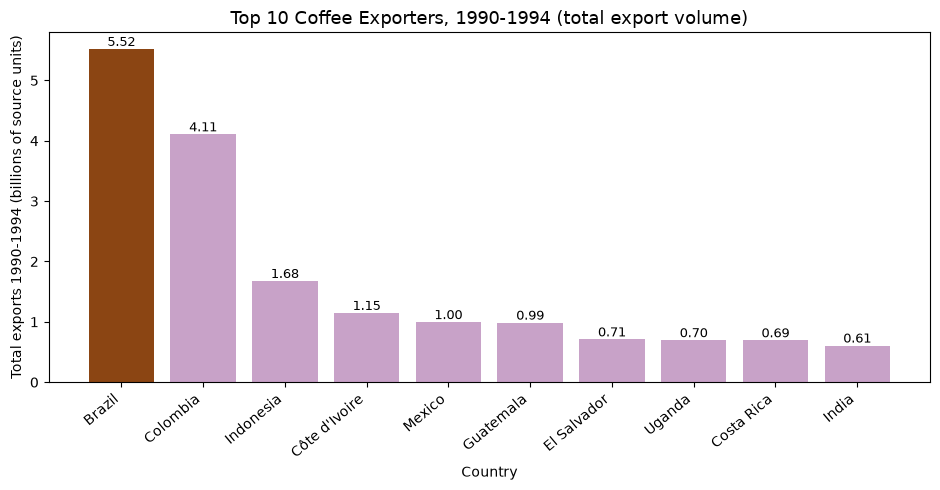

In [3]:
fig, ax = plt.subplots(figsize=(9.5, 5))
colors = ["#8B4513" if c == q1_top10["Country"].iloc[0] else "#C8A2C8"
          for c in q1_top10["Country"]]
ax.bar(q1_top10["Country"], q1_top10["Total exports 1990-1994 (bn)"], color=colors)
ax.set_title("Top 10 Coffee Exporters, 1990-1994 (total export volume)", fontsize=13)
ax.set_xlabel("Country")
ax.set_ylabel("Total exports 1990-1994 (billions of source units)")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
for i, v in enumerate(q1_top10["Total exports 1990-1994 (bn)"]):
    ax.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
fig.tight_layout()
plt.show()

### Stakeholder Summary

From 1990 to 1994, the biggest exporters were Brazil, Colombia, and Indonesia. Colombia and Indonesia were "heavy weights" among these major exporters, accounting for 4 to 5 times the amount of exports than other countries in the data.

### Data Limitations

- Table does not distinguish between Arabica and Robusta.
- Table only tracks bulk exports, not quality, price, or other attributes.

---
## Request 2 — Top Five Coffee Producers

**Scenario:** The sourcing department wants to diversify global suppliers while targeting
regions with robust, stable production capacities.

**Task:** Identify the top five countries with the highest cumulative coffee production
between 1999 and 2004. Return a ranked list (1–5) showing the country and total
production volume.

In [4]:
q2_years = [f"{y}/{str(y + 1)[2:]}" for y in range(1999, 2005)]

q2 = production[["Country"]]
q2["Total production 1999-2004 (bn)"] = (production[q2_years].sum(axis=1) / 1e9).round(3)

q2_top5 = q2.sort_values("Total production 1999-2004 (bn)", ascending=False).head(5).copy()
q2_top5[["Country", "Total production 1999-2004 (bn)"]]

,Country,Total production 1999-2004 (bn)
2,Brazil,13.606
53,Viet Nam,4.851
23,Colombia,3.970
5,Indonesia,2.463
36,India,1.715


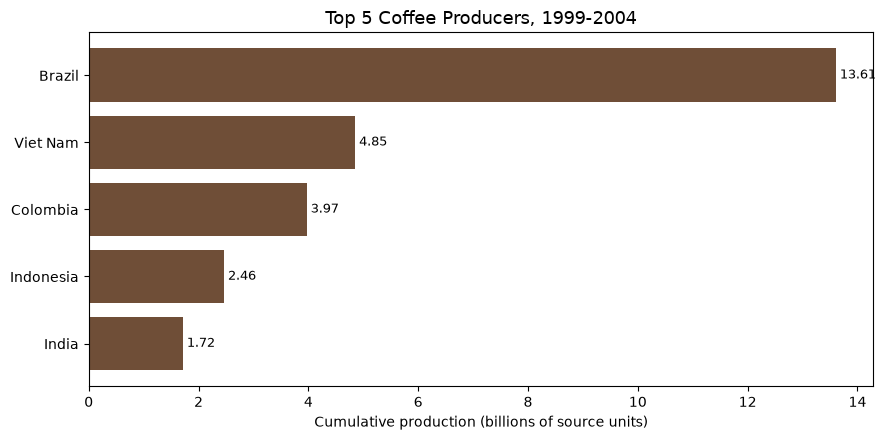

In [5]:
plot_df = q2_top5.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(plot_df["Country"], plot_df["Total production 1999-2004 (bn)"],
               color="#6F4E37")
ax.set_title("Top 5 Coffee Producers, 1999-2004", fontsize=13)
ax.set_xlabel("Cumulative production (billions of source units)")
for bar, v in zip(bars, plot_df["Total production 1999-2004 (bn)"]):
    ax.text(v, bar.get_y() + bar.get_height() / 2, f" {v:.2f}",
            va="center", fontsize=9)
fig.tight_layout()
plt.show()

### Stakeholder Summary

The top 5 coffee producers from 1999 to 2004 include Brazil, Viet Nam, Colombia, Indonesia, and India. Brazil is overwhelmingly the highest coffee producer at about 13.61 billion units of coffee.

### Data Limitations

- Column does not exist solely for 2004, only 2003/2004 and 2004/2005.
- No discernment between production of Arabica and Robusta.

---
## Request 3 — High-Potential "Hidden Gem" Producers

**Scenario:** Rather than focusing exclusively on top-tier market leaders, executives want
to identify strong secondary suppliers that could serve as future strategic partners.

**Task:** For each distinct coffee type (e.g., Arabica, Robusta), determine which country
held the **second-highest** production volume between 1990 and 1994. Handle any
statistical ties appropriately.

In [6]:
q3_years = [f"{y}/{str(y + 1)[2:]}" for y in range(1990, 1995)]

q3_base = production[["Coffee type", "Country"]]
q3_base["production"] = production[q3_years].sum(axis=1)

rows = []
for coffee_type, group in q3_base.groupby("Coffee type"):
    ranked = group.sort_values("production", ascending=False)
    leader = ranked.iloc[0]
    second_value = ranked.loc[ranked["production"] < leader["production"],
                              "production"].max()
    seconds = ranked[ranked["production"] == second_value]
    tie_flag = "Yes" if len(seconds) > 1 else "No"
    for _, s in seconds.iterrows():
        rows.append({
            "Coffee type": coffee_type,
            "Market leader (1st)": leader["Country"],
            "1st volume (bn)": round(leader["production"] / 1e9, 3),
            "Hidden gem (2nd)": s["Country"],
            "2nd volume (bn)": round(s["production"] / 1e9, 3),
            "Tie at 2nd place?": tie_flag,
        })

q3_result = pd.DataFrame(rows)
q3_result

,Coffee type,Market leader (1st),1st volume (bn),Hidden gem (2nd),2nd volume (bn),Tie at 2nd place?
0,Arabica,Colombia,4.303,Ethiopia,0.803,No
1,Arabica/Robusta,Brazil,8.732,Indonesia,2.017,No
2,Robusta,Côte d'Ivoire,0.877,Madagascar,0.247,No


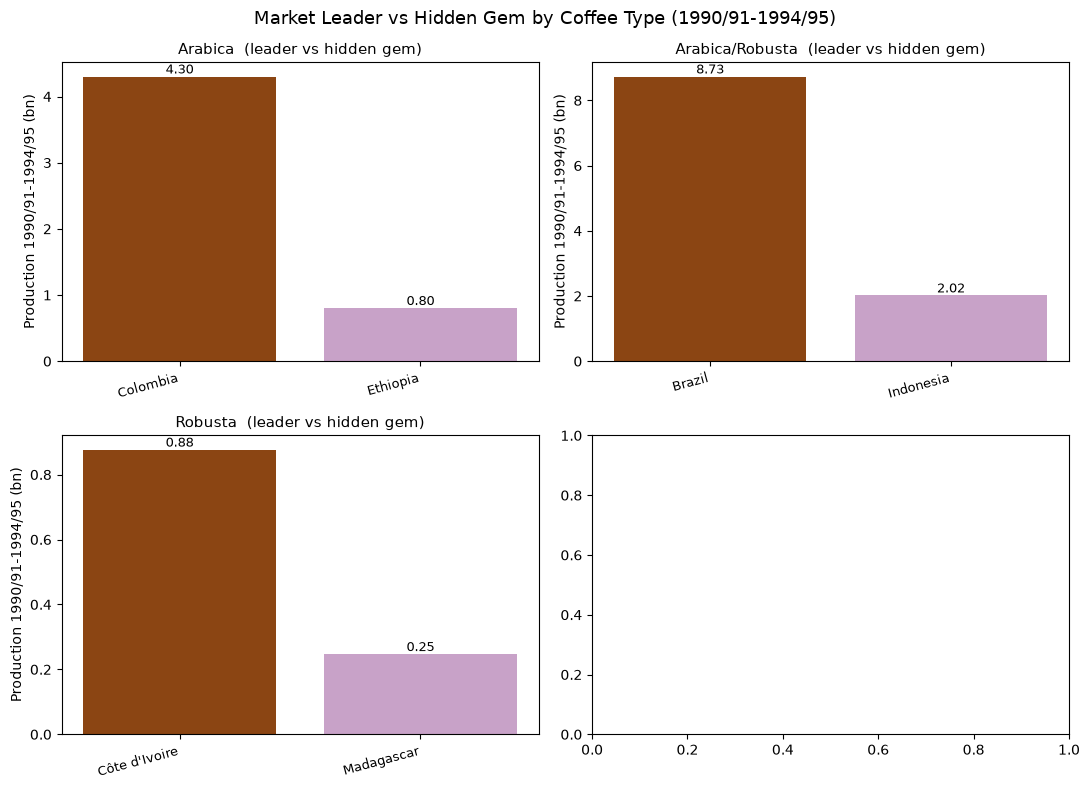

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, coffee_type in zip(axes.flat, q3_result["Coffee type"]):
    ranked = (q3_base[q3_base["Coffee type"] == coffee_type]
             .sort_values("production", ascending=False).head(2))
    vals = ranked["production"] / 1e9
    ax.bar(ranked["Country"], vals, color=["#8B4513", "#C8A2C8"])
    ax.set_title(f"{coffee_type}  (leader vs hidden gem)", fontsize=11)
    ax.set_ylabel("Production 1990/91-1994/95 (bn)")
    plt.setp(ax.get_xticklabels(), rotation=15, ha="right", fontsize=9)
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
fig.suptitle("Market Leader vs Hidden Gem by Coffee Type (1990/91-1994/95)",
             fontsize=13)
fig.tight_layout()
plt.show()

### Stakeholder Summary — Request 3

The hidden gems were identified as Ethiopia for Arabica, Madagascar for Robusta, and Indonesia for both coffee types. Hidden gems had about 4 times less production than leaders in their category.

### Data Limitations — Request 3

- Countries that produce both Arabica and Robusta are under the same category. There is no distinguishing between the production of one or the other.
- Data only indicates the volume, not the price, quality, or other attributes.

---
## Request 4 — Global Coffee Trade Footprints

**Scenario:** The company needs to map out market liquidity and identify the primary
nations moving the global trade needle, whether via importing or exporting.

**Task:** Combine the datasets to calculate each country's total exports and total imports
across the entire timespan, sum them into a final **Total Trade Volume (Imports +
Exports)**, and display the top five countries with the largest total footprint.

In [8]:
footprint = exports[["Country", "Total_export"]].merge(
    imports[["Country", "Total_import"]],
    on="Country", how="outer", indicator=True,
)
footprint["Total_export"] = footprint["Total_export"].fillna(0)
footprint["Total_import"] = footprint["Total_import"].fillna(0)
footprint["Total Trade Volume"] = footprint["Total_export"] + footprint["Total_import"]

q4 = footprint.sort_values("Total Trade Volume", ascending=False).head(5).reset_index(drop=True)
q4_display = pd.DataFrame({
    "Country": q4["Country"],
    "Exports (bn)": (q4["Total_export"] / 1e9).round(2),
    "Imports (bn)": (q4["Total_import"] / 1e9).round(2),
    "Total trade volume (bn)": (q4["Total Trade Volume"] / 1e9).round(2),
})
q4_display

,Country,Exports (bn),Imports (bn),Total trade volume (bn)
0,Brazil,46.34,0.00,46.34
1,United States of America,0.00,42.51,42.51
2,Germany,0.00,31.48,31.48
3,Viet Nam,24.92,0.00,24.92
4,Colombia,19.88,0.00,19.88


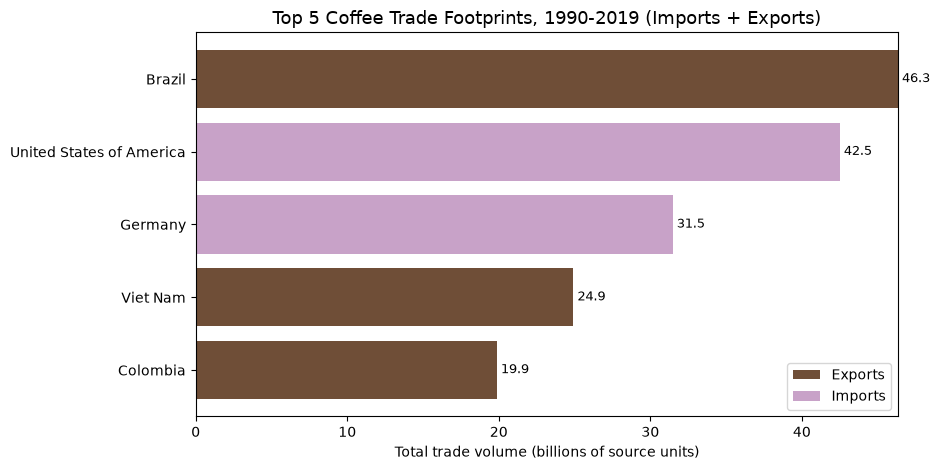

In [10]:
plot_df = q4.iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
exp_vals = plot_df["Total_export"] / 1e9
imp_vals = plot_df["Total_import"] / 1e9
ax.barh(plot_df["Country"], exp_vals, color="#6F4E37", label="Exports")
ax.barh(plot_df["Country"], imp_vals, left=exp_vals, color="#C8A2C8", label="Imports")
ax.set_title("Top 5 Coffee Trade Footprints, 1990-2019 (Imports + Exports)", fontsize=13)
ax.set_xlabel("Total trade volume (billions of source units)")
ax.legend(loc="lower right")
for y, (e, i) in enumerate(zip(exp_vals, imp_vals)):
    ax.text(e + i, y, f" {e + i:.1f}", va="center", fontsize=9)
fig.tight_layout()
plt.show()

### Stakeholder Summary

The countries with the largest total footprint in global coffee trade were the US, Brazil, Germany, Viet Nam, and Colombia. The United States and Germany were the leaders in imports, while Brazil, Viet Nam, and Colombia were the leaders in exports.

### Data Limitations

- Data only indicates the volume, not the price, quality, or other attributes. 

---
## Request 5 — Sourcing Traceability Analysis

**Scenario:** The VP of Supply Chain wants a precise mapping of the global supply network —
specifically tracking exactly which exporting countries supplied each individual
importing country.

**Task:** Investigate whether the available datasets contain the structure necessary to
answer this question. If not, write an executive summary explaining what crucial data
architecture is missing, why the analysis cannot be fulfilled with the current sheets,
and what specific data features or tables would be required.

In [ ]:
exports

,Country,1990,1991,1992,1993,1994,1995,1996,1997,1998,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,Total_import
0,Austria,112800000,123480000,132360000,110160000,85020000,73860000,72600000,77640000,77580000,...,87120000,93540000,93300000,91500000,90780000,89700000,87600000,85740000,86880000,2765760000
1,Belgium,0,0,0,0,0,0,0,0,0,...,349680000,340080000,330120000,312720000,332040000,363120000,340620000,344520000,371940000,6240540000
2,Belgium/Luxembourg,120900000,104760000,109680000,123780000,135720000,144060000,151560000,152640000,214800000,...,0,0,0,0,0,0,0,0,0,1257900000
3,Bulgaria,16080000,12000000,10920000,23820000,27780000,30900000,16320000,17640000,20520000,...,28920000,33600000,36540000,37260000,40920000,46740000,42420000,44220000,47100000,830700000
4,Croatia,0,0,10080000,9780000,11580000,19200000,19320000,23100000,20340000,...,23460000,23040000,24780000,25200000,26220000,28740000,26340000,26760000,27960000,622080000
5,Cyprus,3000000,3240000,2460000,4620000,3120000,2640000,3120000,2460000,3000000,...,4920000,5040000,5640000,5640000,5340000,5580000,6000000,7980000,7980000,130380000
6,Czechia,39540000,31500000,28500000,30840000,33240000,33180000,31500000,33600000,45900000,...,57120000,67620000,71040000,109380000,124080000,106740000,90420000,114180000,96540000,1816020000
7,Denmark,57540000,58980000,63720000,59640000,61980000,52620000,60360000,56940000,60840000,...,54540000,54780000,55260000,51180000,50460000,54360000,51120000,52080000,54480000,1741860000
8,Estonia,0,0,960000,3060000,4980000,6420000,7020000,8460000,8100000,...,10020000,9420000,9360000,7860000,7560000,8100000,7980000,8820000,8880000,268980000
9,Finland,65700000,61980000,63300000,78060000,81660000,46140000,59520000,71160000,70080000,...,77220000,74280000,76500000,72780000,79260000,83340000,81600000,77100000,90900000,2151840000


In [ ]:
imports

,Country,1990,1991,1992,1993,1994,1995,1996,1997,1998,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,Total_import
0,Austria,112800000,123480000,132360000,110160000,85020000,73860000,72600000,77640000,77580000,...,87120000,93540000,93300000,91500000,90780000,89700000,87600000,85740000,86880000,2765760000
1,Belgium,0,0,0,0,0,0,0,0,0,...,349680000,340080000,330120000,312720000,332040000,363120000,340620000,344520000,371940000,6240540000
2,Belgium/Luxembourg,120900000,104760000,109680000,123780000,135720000,144060000,151560000,152640000,214800000,...,0,0,0,0,0,0,0,0,0,1257900000
3,Bulgaria,16080000,12000000,10920000,23820000,27780000,30900000,16320000,17640000,20520000,...,28920000,33600000,36540000,37260000,40920000,46740000,42420000,44220000,47100000,830700000
4,Croatia,0,0,10080000,9780000,11580000,19200000,19320000,23100000,20340000,...,23460000,23040000,24780000,25200000,26220000,28740000,26340000,26760000,27960000,622080000
5,Cyprus,3000000,3240000,2460000,4620000,3120000,2640000,3120000,2460000,3000000,...,4920000,5040000,5640000,5640000,5340000,5580000,6000000,7980000,7980000,130380000
6,Czechia,39540000,31500000,28500000,30840000,33240000,33180000,31500000,33600000,45900000,...,57120000,67620000,71040000,109380000,124080000,106740000,90420000,114180000,96540000,1816020000
7,Denmark,57540000,58980000,63720000,59640000,61980000,52620000,60360000,56940000,60840000,...,54540000,54780000,55260000,51180000,50460000,54360000,51120000,52080000,54480000,1741860000
8,Estonia,0,0,960000,3060000,4980000,6420000,7020000,8460000,8100000,...,10020000,9420000,9360000,7860000,7560000,8100000,7980000,8820000,8880000,268980000
9,Finland,65700000,61980000,63300000,78060000,81660000,46140000,59520000,71160000,70080000,...,77220000,74280000,76500000,72780000,79260000,83340000,81600000,77100000,90900000,2151840000


### Executive Summary

No, the current data architecture does not support a sourcing-traceability map. The data structure that is missing is a link between exports and imports or a source of where each of the imports originate from. The analysis cannot be fulfilled with the current sheets because they only contain simple data about aggregate imports and exports. There are no details in the data about where the imports originate or where the exports are going. The data that would be required is a table for each country containing breakdown of how many units are exported to or imported from another country.